# Outcome vs Uncertainty — 1 BTG

Plots:
1. T1 BCAS death rate vs selected uncertainty
2. Fraction of T2 treated within NATO timeline vs selected uncertainty

In [4]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))
import paths

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ── CONFIGURATION ────────────────────────────────────────────────────────────
FOLDER_NAME = "20260604_143324_scenario_1ccp_1btg_wave_exploration"
UNCERTAINTY = "wave_duration_min"   # <-- change this to any uncertainty column
# ─────────────────────────────────────────────────────────────────────────────

df = pd.read_csv(paths.MULTI_RUN_OUTPUT / FOLDER_NAME / "results.csv")
levels = sorted(df[UNCERTAINTY].unique())
print(f"Loaded {len(df)} runs  |  {UNCERTAINTY} levels: {levels}")

Loaded 1500 runs  |  wave_duration_min levels: [np.int64(1), np.int64(5), np.int64(10), np.int64(15), np.int64(20), np.int64(25), np.int64(30), np.int64(35), np.int64(40), np.int64(45), np.int64(50), np.int64(55), np.int64(60), np.int64(120), np.int64(240)]


In [5]:
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import matplotlib.gridspec as gridspec

def median_ci(vals, n_boot=1000, alpha=0.05):
    """Bootstrap 95% CI half-width for the median."""
    if len(vals) < 2:
        return np.nan
    rng = np.random.default_rng(42)
    boots = np.array([np.median(rng.choice(vals, size=len(vals))) for _ in range(n_boot)])
    lo, hi = np.percentile(boots, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return (hi - lo) / 2

def plot_diagnostic_matrix(rows, triage_label):
    """
    Heatmap with dual colour scales.
    Each row is (label, column_name) or (label, column_name, agg)
    where agg is 'median' (default), 'q25', or 'q75'.
    Rows whose label starts with 'Mortality' use Reds; all others use Blues.
    """
    rows_norm = [(r[0], r[1], r[2] if len(r) > 2 else "median") for r in rows]

    matrix = pd.DataFrame(index=[r[0] for r in rows_norm], columns=[str(lv) for lv in levels], dtype=float)
    ci_mat = pd.DataFrame(index=[r[0] for r in rows_norm], columns=[str(lv) for lv in levels], dtype=float)

    for label, col, agg in rows_norm:
        for lv in levels:
            vals = df.loc[df[UNCERTAINTY] == lv, col].dropna().values
            if len(vals) == 0:
                matrix.loc[label, str(lv)] = np.nan
                ci_mat.loc[label, str(lv)] = np.nan
                continue
            if agg == "q25":
                matrix.loc[label, str(lv)] = np.percentile(vals, 25)
            elif agg == "q75":
                matrix.loc[label, str(lv)] = np.percentile(vals, 75)
            else:
                matrix.loc[label, str(lv)] = np.median(vals)
            ci_mat.loc[label, str(lv)] = median_ci(vals)

    mort_idx = [i for i, (lab, _, __) in enumerate(rows_norm) if lab.startswith("Mortality")]
    wait_idx = [i for i in range(len(rows_norm)) if i not in mort_idx]

    vals_f = matrix.values.astype(float)
    wait_vals = vals_f[wait_idx, :].flatten()
    mort_vals = vals_f[mort_idx, :].flatten()
    norm_wait = Normalize(vmin=np.nanmin(wait_vals), vmax=np.nanmax(wait_vals))
    norm_mort = Normalize(vmin=np.nanmin(mort_vals), vmax=np.nanmax(mort_vals))
    cmap_wait = plt.cm.Blues
    cmap_mort = plt.cm.Reds

    n_rows, n_cols = vals_f.shape

    fig = plt.figure(figsize=(max(9, n_cols * 1.5 + 2), n_rows * 0.85 + 1.5))
    gs = gridspec.GridSpec(2, 2, width_ratios=[1, 0.03], height_ratios=[1, 1],
                           wspace=0.05, hspace=0.08)
    ax = fig.add_subplot(gs[:, 0])
    cax_w = fig.add_subplot(gs[0, 1])
    cax_m = fig.add_subplot(gs[1, 1])

    for i in range(n_rows):
        is_mort = i in mort_idx
        norm = norm_mort if is_mort else norm_wait
        cmap = cmap_mort if is_mort else cmap_wait
        for j in range(n_cols):
            v = vals_f[i, j]
            color = cmap(norm(v)) if not np.isnan(v) else (0.95, 0.95, 0.95, 1)
            ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, facecolor=color, edgecolor="white", lw=1.5))
            if not np.isnan(v):
                ci = ci_mat.iloc[i, j]
                txt = f"{v:.3f}\n(±{ci:.3f})" if not np.isnan(ci) else f"{v:.3f}"
                brightness = 0.299 * color[0] + 0.587 * color[1] + 0.114 * color[2]
                ax.text(j, i, txt, ha="center", va="center", fontsize=8,
                        color="white" if brightness < 0.55 else "black")

    ax.set_xlim(-0.5, n_cols - 0.5)
    ax.set_ylim(n_rows - 0.5, -0.5)
    ax.set_xticks(range(n_cols))
    ax.set_xticklabels([str(lv) for lv in levels])
    ax.set_yticks(range(n_rows))
    ax.set_yticklabels([r[0] for r in rows_norm])
    ax.set_xlabel(UNCERTAINTY)
    ax.set_title(f"{triage_label} Diagnostic Matrix — per {UNCERTAINTY} level")

    fig.colorbar(ScalarMappable(norm=norm_wait, cmap=cmap_wait), cax=cax_w, label="Wait (min)")
    fig.colorbar(ScalarMappable(norm=norm_mort, cmap=cmap_mort), cax=cax_m, label="Mortality rate")

    plt.tight_layout()
    plt.show()
    print(matrix.to_string(float_format="%.4f"))
    return matrix

def boxplot_by_uncertainty(outcome, ylabel, title, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 5))
    data = [df.loc[df[UNCERTAINTY] == lv, outcome].dropna().values for lv in levels]
    bp = ax.boxplot(data, labels=[str(lv) for lv in levels], patch_artist=True, widths=0.5)
    for patch in bp["boxes"]:
        patch.set_facecolor("steelblue")
        patch.set_alpha(0.7)
    for i, d in enumerate(data):
        if len(d) > 0:
            med = np.median(d)
            ax.text(i + 1, med, f"  {med:.3f}", va="center", fontsize=9, fontweight="bold")
    ax.set_xlabel(UNCERTAINTY)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    return ax

## 1. T1 BCAS Death Rate

C:\Users\User\AppData\Local\Temp\ipykernel_5440\3802913015.py:97: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=[str(lv) for lv in levels], patch_artist=True, widths=0.5)


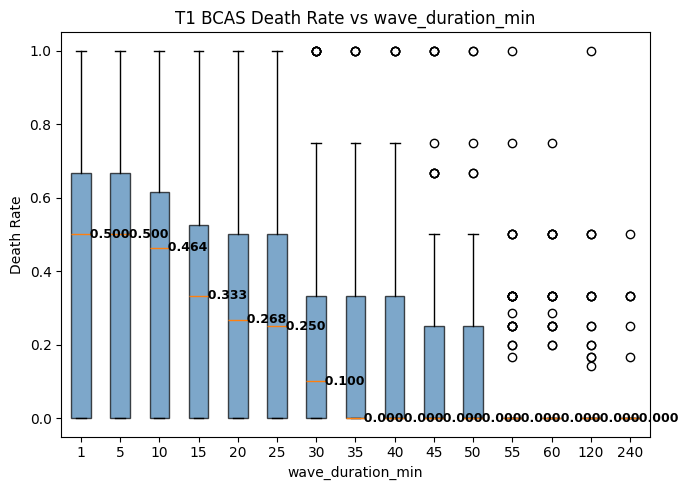

                    mean  median    std    min    max
wave_duration_min                                    
1                 0.4579  0.5000 0.3424 0.0000 1.0000
5                 0.4424  0.5000 0.3365 0.0000 1.0000
10                0.4084  0.4643 0.3373 0.0000 1.0000
15                0.3702  0.3333 0.3390 0.0000 1.0000
20                0.3100  0.2679 0.3193 0.0000 1.0000
25                0.2886  0.2500 0.3139 0.0000 1.0000
30                0.2274  0.1000 0.2864 0.0000 1.0000
35                0.1683  0.0000 0.2658 0.0000 1.0000
40                0.1668  0.0000 0.2629 0.0000 1.0000
45                0.1590  0.0000 0.2640 0.0000 1.0000
50                0.1241  0.0000 0.2215 0.0000 1.0000
55                0.0852  0.0000 0.1806 0.0000 1.0000
60                0.0694  0.0000 0.1560 0.0000 0.7500
120               0.0521  0.0000 0.1492 0.0000 1.0000
240               0.0192  0.0000 0.0802 0.0000 0.5000


In [6]:
fig, ax = plt.subplots(figsize=(7, 5))
boxplot_by_uncertainty("death_rate_T1_BCAS", "Death Rate", f"T1 BCAS Death Rate vs {UNCERTAINTY}", ax=ax)
plt.tight_layout()
plt.show()

print(df.groupby(UNCERTAINTY)["death_rate_T1_BCAS"].agg(["mean", "median", "std", "min", "max"]).to_string(float_format="%.4f"))

## 2. Fraction of T2 Within NATO Timeline

C:\Users\User\AppData\Local\Temp\ipykernel_5440\3802913015.py:97: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=[str(lv) for lv in levels], patch_artist=True, widths=0.5)


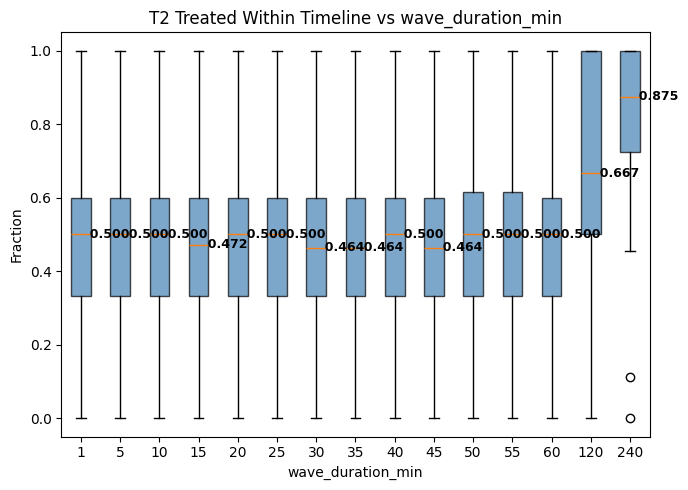

                    mean  median    std    min    max
wave_duration_min                                    
1                 0.4765  0.5000 0.2314 0.0000 1.0000
5                 0.4742  0.5000 0.2362 0.0000 1.0000
10                0.4742  0.5000 0.2362 0.0000 1.0000
15                0.4768  0.4722 0.2338 0.0000 1.0000
20                0.4767  0.5000 0.2324 0.0000 1.0000
25                0.4813  0.5000 0.2335 0.0000 1.0000
30                0.4757  0.4643 0.2342 0.0000 1.0000
35                0.4729  0.4643 0.2343 0.0000 1.0000
40                0.4742  0.5000 0.2362 0.0000 1.0000
45                0.4742  0.4643 0.2362 0.0000 1.0000
50                0.4834  0.5000 0.2340 0.0000 1.0000
55                0.4928  0.5000 0.2316 0.0000 1.0000
60                0.5035  0.5000 0.2283 0.0000 1.0000
120               0.6769  0.6667 0.2427 0.0000 1.0000
240               0.8423  0.8750 0.1889 0.0000 1.0000


In [7]:
fig, ax = plt.subplots(figsize=(7, 5))
boxplot_by_uncertainty("frac_t2_within_timeline", "Fraction", f"T2 Treated Within Timeline vs {UNCERTAINTY}", ax=ax)
plt.tight_layout()
plt.show()

print(df.groupby(UNCERTAINTY)["frac_t2_within_timeline"].agg(["mean", "median", "std", "min", "max"]).to_string(float_format="%.4f"))

## 3. Diagnostic Matrix — T1

C:\Users\User\AppData\Local\Temp\ipykernel_5440\3802913015.py:88: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


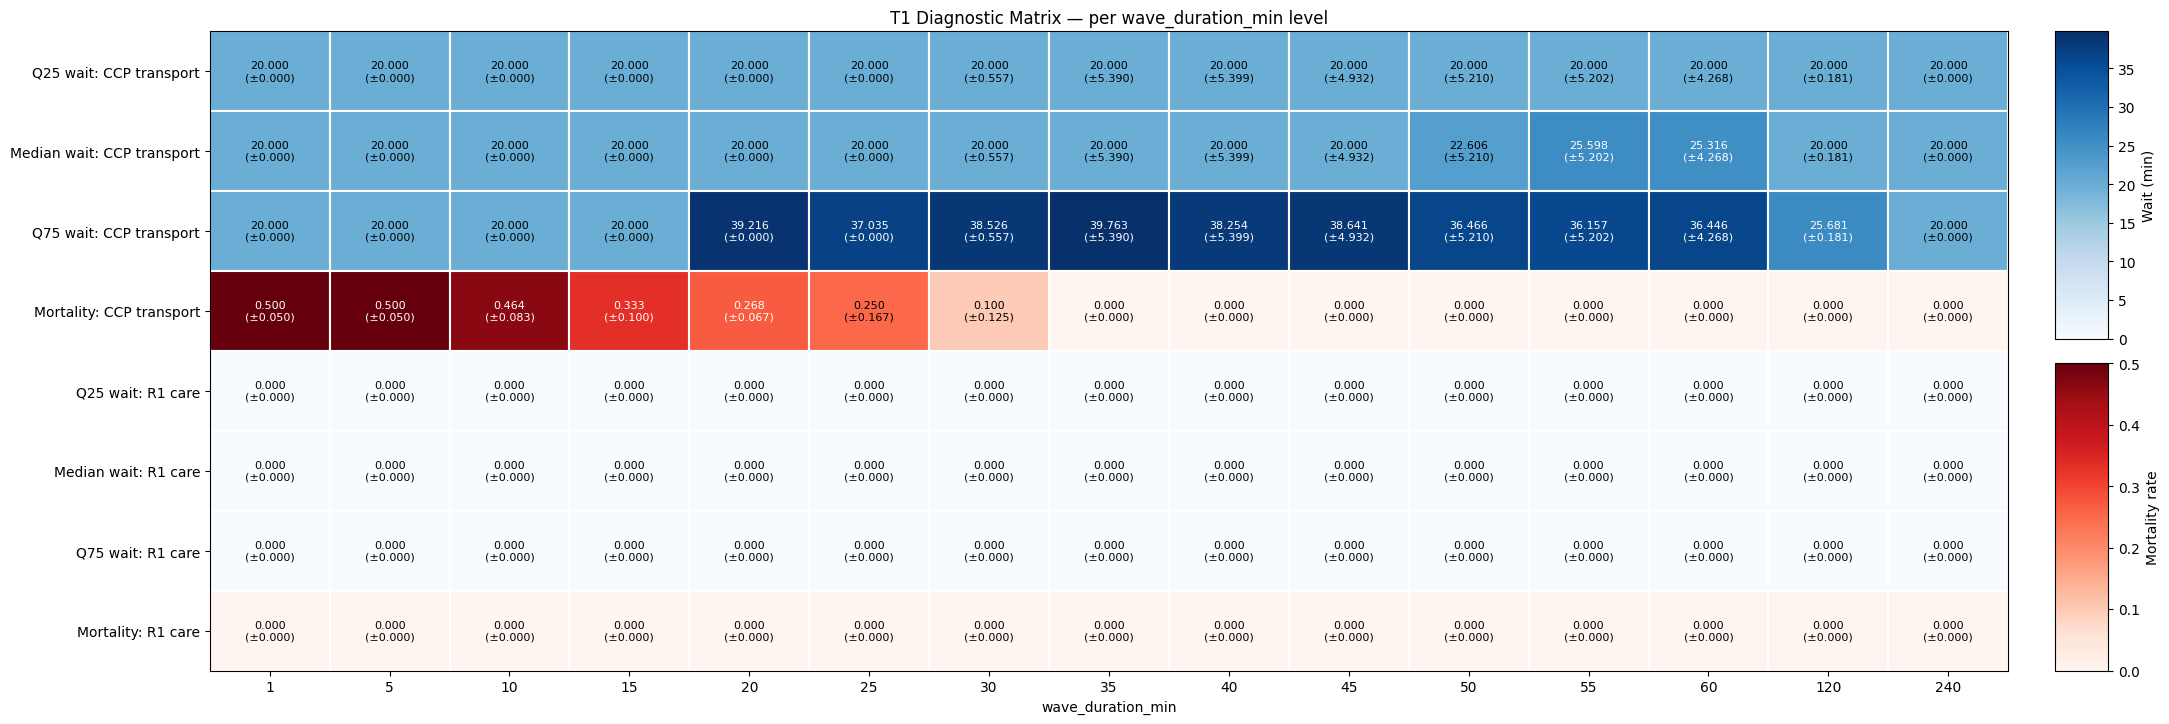

                                 1       5      10      15      20      25      30      35      40      45      50      55      60     120     240
Q25 wait: CCP transport    20.0000 20.0000 20.0000 20.0000 20.0000 20.0000 20.0000 20.0000 20.0000 20.0000 20.0000 20.0000 20.0000 20.0000 20.0000
Median wait: CCP transport 20.0000 20.0000 20.0000 20.0000 20.0000 20.0000 20.0000 20.0000 20.0000 20.0000 22.6056 25.5980 25.3158 20.0000 20.0000
Q75 wait: CCP transport    20.0000 20.0000 20.0000 20.0000 39.2163 37.0346 38.5258 39.7635 38.2538 38.6411 36.4658 36.1565 36.4460 25.6808 20.0000
Mortality: CCP transport    0.5000  0.5000  0.4643  0.3333  0.2679  0.2500  0.1000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000
Q25 wait: R1 care           0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000
Median wait: R1 care        0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.

,1,5,10,15,20,25,30,35,40,45,50,55,60,120,240
Q25 wait: CCP transport,20.0,20.0,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.0
Median wait: CCP transport,20.0,20.0,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,22.605584,25.598013,25.315819,20.000000,20.0
Q75 wait: CCP transport,20.0,20.0,20.000000,20.000000,39.216326,37.034552,38.525835,39.763452,38.253793,38.641143,36.465809,36.156505,36.446005,25.680801,20.0
Mortality: CCP transport,0.5,0.5,0.464286,0.333333,0.267857,0.250000,0.100000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0
Q25 wait: R1 care,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0
Median wait: R1 care,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0
Q75 wait: R1 care,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0
Mortality: R1 care,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0


In [8]:
t1_rows = [
    ("Q25 wait: CCP transport",     "median_wait_ccp_transport_T1", "q25"),
    ("Median wait: CCP transport",  "median_wait_ccp_transport_T1"),
    ("Q75 wait: CCP transport",     "median_wait_ccp_transport_T1", "q75"),
    ("Mortality: CCP transport",    "mortality_ccp_transport_T1"),
    ("Q25 wait: R1 care",           "median_wait_r1_care_T1", "q25"),
    ("Median wait: R1 care",        "median_wait_r1_care_T1"),
    ("Q75 wait: R1 care",           "median_wait_r1_care_T1", "q75"),
    ("Mortality: R1 care",          "mortality_r1_care_T1"),
    # ("Q25 wait: R1 transport",      "median_wait_r1_transport_T1", "q25"),
    # ("Median wait: R1 transport",   "median_wait_r1_transport_T1"),
    # ("Q75 wait: R1 transport",      "median_wait_r1_transport_T1", "q75"),
    # ("Mortality: R1 transport",     "mortality_r1_transport_T1"),
    # ("Q25 wait: R2 care",           "median_wait_r2_care_T1", "q25"),
    # ("Median wait: R2 care",        "median_wait_r2_care_T1"),
    # ("Q75 wait: R2 care",           "median_wait_r2_care_T1", "q75"),
    # ("Mortality: R2 care",          "mortality_r2_care_T1"),
]

plot_diagnostic_matrix(t1_rows, "T1")

## 4. Diagnostic Matrix — T2

C:\Users\User\AppData\Local\Temp\ipykernel_5440\3802913015.py:88: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


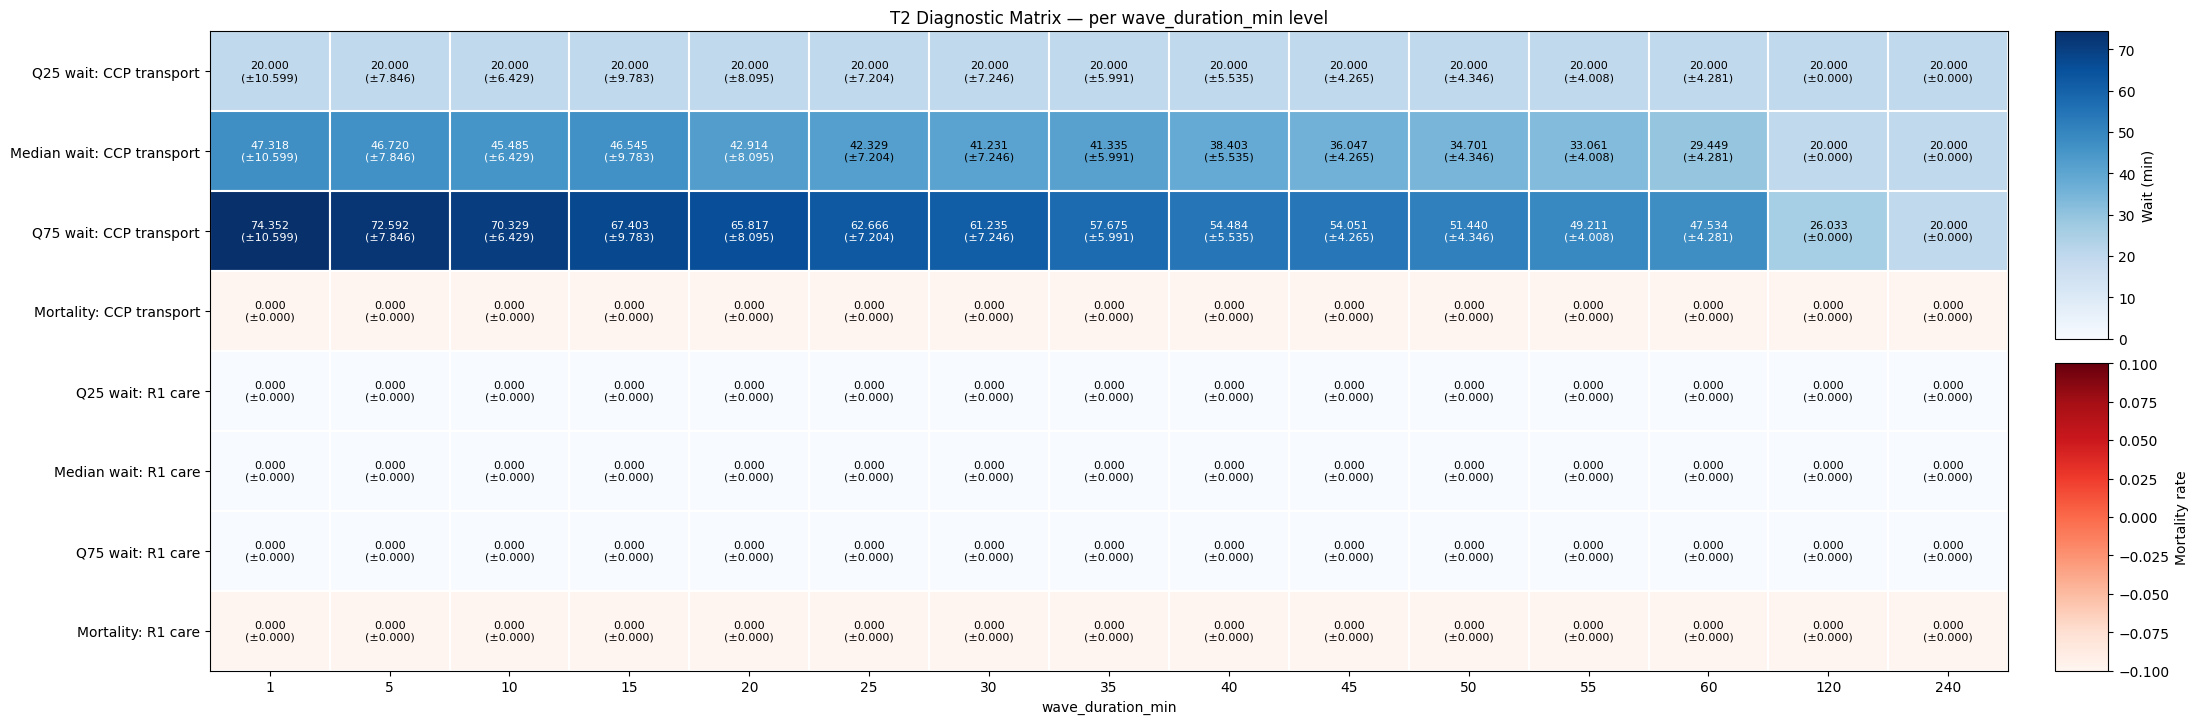

                                 1       5      10      15      20      25      30      35      40      45      50      55      60     120     240
Q25 wait: CCP transport    20.0000 20.0000 20.0000 20.0000 20.0000 20.0000 20.0000 20.0000 20.0000 20.0000 20.0000 20.0000 20.0000 20.0000 20.0000
Median wait: CCP transport 47.3176 46.7198 45.4850 46.5449 42.9136 42.3290 41.2312 41.3347 38.4035 36.0474 34.7007 33.0611 29.4490 20.0000 20.0000
Q75 wait: CCP transport    74.3516 72.5918 70.3289 67.4030 65.8166 62.6663 61.2355 57.6754 54.4839 54.0508 51.4398 49.2112 47.5336 26.0329 20.0000
Mortality: CCP transport    0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000
Q25 wait: R1 care           0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000
Median wait: R1 care        0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.

,1,5,10,15,20,25,30,35,40,45,50,55,60,120,240
Q25 wait: CCP transport,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.0
Median wait: CCP transport,47.317626,46.719776,45.484956,46.544899,42.913560,42.328951,41.231245,41.334661,38.403469,36.047378,34.700713,33.061125,29.448966,20.000000,20.0
Q75 wait: CCP transport,74.351610,72.591765,70.328924,67.403025,65.816627,62.666255,61.235459,57.675415,54.483868,54.050825,51.439796,49.211191,47.533573,26.032898,20.0
Mortality: CCP transport,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0
Q25 wait: R1 care,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0
Median wait: R1 care,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0
Q75 wait: R1 care,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0
Mortality: R1 care,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0


In [9]:
t2_rows = [
    ("Q25 wait: CCP transport",     "median_wait_ccp_transport_T2", "q25"),
    ("Median wait: CCP transport",  "median_wait_ccp_transport_T2"),
    ("Q75 wait: CCP transport",     "median_wait_ccp_transport_T2", "q75"),
    ("Mortality: CCP transport",    "mortality_ccp_transport_T2"),
    ("Q25 wait: R1 care",           "median_wait_r1_care_T2", "q25"),
    ("Median wait: R1 care",        "median_wait_r1_care_T2"),
    ("Q75 wait: R1 care",           "median_wait_r1_care_T2", "q75"),
    ("Mortality: R1 care",          "mortality_r1_care_T2"),
    # ("Q25 wait: R1 transport",      "median_wait_r1_transport_T2", "q25"),
    # ("Median wait: R1 transport",   "median_wait_r1_transport_T2"),
    # ("Q75 wait: R1 transport",      "median_wait_r1_transport_T2", "q75"),
    # ("Mortality: R1 transport",     "mortality_r1_transport_T2"),
    # ("Q25 wait: R2 care",           "median_wait_r2_care_T2", "q25"),
    # ("Median wait: R2 care",        "median_wait_r2_care_T2"),
    # ("Q75 wait: R2 care",           "median_wait_r2_care_T2", "q75"),
    # ("Mortality: R2 care",          "mortality_r2_care_T2"),
]

plot_diagnostic_matrix(t2_rows, "T2")